# Credit Score — entrenamiento mejorado

Objetivo: producir una **probabilidad de default (PD)** y convertirla a un score que sea estable y coherente con los cambios de las variables.

Cambios clave respecto al notebook anterior:
- No se usan variables sintéticas para enseñar al modelo relaciones que no existen en los datos reales.
- No se usa `score_bruto_actual`, porque era un score artificial con ruido.
- Se usan directamente variables reales de morosidad del dataset.
- Se evita `class_weight="balanced"` porque el objetivo final es una PD calibrada.
- Se agrega un modelo de árboles con **restricciones monotónicas** como candidato para producción.
- El score final se construye desde odds/PD, no desde una transformación lineal arbitraria de la probabilidad.
- Se incluyen pruebas automáticas de coherencia para detectar respuestas contraintuitivas.

> La búsqueda de hiperparámetros del modelo monotónico está marcada como cómputo pesado para que la ejecutes localmente.

In [2]:
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer, RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import roc_auc_score, brier_score_loss, roc_curve
from scipy.stats import ks_2samp

RANDOM_STATE = 42
PATH_CSV = r"cs-training.csv"

## 1. Carga y adaptación del dataset

A diferencia del notebook anterior, aquí conservamos las variables reales de morosidad. No fabricamos `tipo_vivienda`, `situacion_laboral` ni antigüedades para entrenar el modelo.

In [3]:
raw = pd.read_csv(PATH_CSV, index_col=0)

RENAME = {
    'SeriousDlqin2yrs': 'target',
    'age': 'edad',
    'MonthlyIncome': 'ingreso_neto_mensual',
    'DebtRatio': 'relacion_deuda_ingreso',
    'NumberOfOpenCreditLinesAndLoans': 'cantidad_creditos_activos',
    'RevolvingUtilizationOfUnsecuredLines': 'utilizacion_lineas',
    'NumberOfTime30-59DaysPastDueNotWorse': 'atraso_30_59',
    'NumberOfTime60-89DaysPastDueNotWorse': 'atraso_60_89',
    'NumberOfTimes90DaysLate': 'atraso_90_plus',
    'NumberRealEstateLoansOrLines': 'creditos_inmobiliarios',
    'NumberOfDependents': 'dependientes',
}

df = raw.rename(columns=RENAME).copy()

df = df.replace([np.inf, -np.inf], np.nan)
df = df[df['edad'].between(18, 100)]
df = df[df['relacion_deuda_ingreso'].between(0, 2)]
df = df[df['target'].isin([0, 1])]

# Mantener el ingreso faltante como faltante: no inventarlo en esta etapa.
print('Registros:', len(df))
print('Default:', df['target'].mean())
print(df[['edad','ingreso_neto_mensual','relacion_deuda_ingreso',
          'utilizacion_lineas','atraso_30_59','atraso_60_89',
          'atraso_90_plus']].describe())

Registros: 118947
Default: 0.06955198533800769
                edad  ingreso_neto_mensual  relacion_deuda_ingreso  \
count  118947.000000          1.169620e+05           118947.000000   
mean       51.464661          6.835629e+03                0.338566   
std        14.585216          1.454822e+04                0.296034   
min        21.000000          0.000000e+00                0.000000   
25%        41.000000          3.500000e+03                0.132314   
50%        51.000000          5.500000e+03                0.284723   
75%        62.000000          8.333000e+03                0.461372   
max        99.000000          3.008750e+06                2.000000   

       utilizacion_lineas   atraso_30_59   atraso_60_89  atraso_90_plus  
count       118947.000000  118947.000000  118947.000000   118947.000000  
mean             5.843150       0.456119       0.265219        0.290087  
std            257.137976       4.450833       4.414560        4.427698  
min              0.000000 

## 2. Variables del modelo

Estas variables son observables directamente en el dataset. `score_bruto_actual` queda fuera porque era una construcción artificial del notebook anterior.

Las variables de ingreso/deuda se mantienen en sus unidades originales del dataset. Para la app, el mismo valor debe pasar por exactamente la misma transformación que durante entrenamiento.

In [4]:
FEATURES = [
    'edad',
    'ingreso_neto_mensual',
    'relacion_deuda_ingreso',
    'utilizacion_lineas',
    'atraso_30_59',
    'atraso_60_89',
    'atraso_90_plus',
    'cantidad_creditos_activos',
    'creditos_inmobiliarios',
    'dependientes',
]

X = df[FEATURES].copy()
y = df['target'].copy()

# Tres conjuntos: train / validación / test.
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25,
    random_state=RANDOM_STATE, stratify=y_train_val
)

print(f'Train: {len(X_train):,}')
print(f'Val  : {len(X_val):,}')
print(f'Test : {len(X_test):,}')
print(f'Default train={y_train.mean():.3%} | val={y_val.mean():.3%} | test={y_test.mean():.3%}')

Train: 71,367
Val  : 23,790
Test : 23,790
Default train=6.954% | val=6.957% | test=6.957%


## 3. Modelo base: regresión logística

Este modelo sirve como referencia porque su comportamiento es mucho más estable y fácil de auditar que un Random Forest para un scorecard. No usamos `class_weight="balanced"`.

In [5]:
LOG_SKEWED = ['ingreso_neto_mensual']
LOG_STANDARD = [
    'edad', 'relacion_deuda_ingreso', 'utilizacion_lineas',
    'atraso_30_59', 'atraso_60_89', 'atraso_90_plus',
    'cantidad_creditos_activos', 'creditos_inmobiliarios', 'dependientes'
]

pre_lr = ColumnTransformer([
    ('log', Pipeline([
        ('imp', SimpleImputer(strategy='median')),
        ('log1p', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
        ('sc', StandardScaler()),
    ]), LOG_SKEWED),
    ('std', Pipeline([
        ('imp', SimpleImputer(strategy='median', add_indicator=True)),
        ('sc', RobustScaler()),
    ]), LOG_STANDARD),
])

lr_model = Pipeline([
    ('prep', pre_lr),
    ('model', LogisticRegression(
        C=0.2,
        solver='lbfgs',
        max_iter=2000,
        class_weight=None,
        random_state=RANDOM_STATE,
    ))
])

lr_model.fit(X_train, y_train)
p_lr_val = lr_model.predict_proba(X_val)[:, 1]
print('LR AUC val:', roc_auc_score(y_val, p_lr_val))
print('LR Brier val:', brier_score_loss(y_val, p_lr_val))

LR AUC val: 0.7032181675614552
LR Brier val: 0.05982309292195947


## 4. Modelo monotónico — recomendado como challenger

Este modelo aprende relaciones no lineales, pero se le imponen restricciones sobre variables donde la dirección de riesgo debe ser consistente:

- más ingreso → no debe aumentar el default;
- más DTI → no debe disminuir el default;
- más utilización → no debe disminuir el default;
- más atrasos → no debe disminuir el default.

Para variables cuya dirección no es universalmente monotónica (`edad`, cantidad de créditos, dependientes, inmuebles), se deja restricción `0`.

In [6]:
MONO_FEATURES = FEATURES
MONO_CST = [
    0,   # edad
    -1,  # ingreso_neto_mensual
    +1,  # relacion_deuda_ingreso
    +1,  # utilizacion_lineas
    +1,  # atraso_30_59
    +1,  # atraso_60_89
    +1,  # atraso_90_plus
    0,   # cantidad_creditos_activos
    0,   # creditos_inmobiliarios
    0,   # dependientes
]

hgb = HistGradientBoostingClassifier(
    learning_rate=0.05,
    max_iter=300,
    max_leaf_nodes=15,
    min_samples_leaf=100,
    l2_regularization=1.0,
    monotonic_cst=MONO_CST,
    random_state=RANDOM_STATE,
)

hgb_pipe = Pipeline([
    ('imp', SimpleImputer(strategy='median')),
    ('model', hgb),
])

hgb_pipe.fit(X_train, y_train)
p_hgb_val = hgb_pipe.predict_proba(X_val)[:, 1]
print('HGB monotónico AUC val:', roc_auc_score(y_val, p_hgb_val))
print('HGB monotónico Brier val:', brier_score_loss(y_val, p_hgb_val))

HGB monotónico AUC val: 0.8583265010028411
HGB monotónico Brier val: 0.05183394807156347


## 5. Búsqueda de hiperparámetros — CÓMPUTO PESADO

Ejecutá esta celda en tu PC. No es necesario ejecutarla mientras depurás el pipeline.

In [7]:
PARAMS_HGB = {
    'model__learning_rate': [0.02, 0.03, 0.05, 0.08],
    'model__max_iter': [150, 250, 400, 600],
    'model__max_leaf_nodes': [7, 11, 15, 23, 31],
    'model__min_samples_leaf': [50, 100, 150, 250, 400],
    'model__l2_regularization': [0.0, 0.1, 1.0, 3.0, 10.0],
}

search_hgb = RandomizedSearchCV(
    hgb_pipe,
    PARAMS_HGB,
    n_iter=30,
    scoring='roc_auc',
    cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=2,
    refit=True,
)

search_hgb.fit(X_train, y_train)
print('Mejores parámetros:')
print(search_hgb.best_params_)
print('AUC CV:', search_hgb.best_score_)

hgb_best = search_hgb.best_estimator_

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Mejores parámetros:
{'model__min_samples_leaf': 100, 'model__max_leaf_nodes': 31, 'model__max_iter': 250, 'model__learning_rate': 0.02, 'model__l2_regularization': 10.0}
AUC CV: 0.8552592341789282


## 6. Calibración de PD

El objetivo del score no es solamente ordenar clientes. La PD debe ser razonable. Por eso medimos AUC **y** Brier/calibración.

`Sigmoid` suele ser un buen primer paso para evitar sobreajuste de calibración. La calibración no debe tocar el conjunto de test.

In [8]:
# Seleccionar el HGB optimizado si existe; de lo contrario usar el modelo base.
base_for_calibration = globals().get('hgb_best', hgb_pipe)

calibrated_model = CalibratedClassifierCV(
    estimator=base_for_calibration,
    method='sigmoid',
    cv=5,
)
calibrated_model.fit(X_train, y_train)

p_cal_val = calibrated_model.predict_proba(X_val)[:, 1]
print('Calibrado AUC val:', roc_auc_score(y_val, p_cal_val))
print('Calibrado Brier val:', brier_score_loss(y_val, p_cal_val))

Calibrado AUC val: 0.8588532603762821
Calibrado Brier val: 0.05174169427835233


## 7. Evaluación final — usar Test una sola vez

In [9]:
def metricas(y_true, p, nombre):
    auc = roc_auc_score(y_true, p)
    gini = 2 * auc - 1
    brier = brier_score_loss(y_true, p)
    ks, _ = ks_2samp(p[y_true == 0], p[y_true == 1])
    print(f'{nombre:<24} AUC={auc:.4f} | Gini={gini:.4f} | KS={ks:.4f} | Brier={brier:.5f}')
    return {'auc': auc, 'gini': gini, 'ks': ks, 'brier': brier}

p_lr_test = lr_model.predict_proba(X_test)[:, 1]
p_cal_test = calibrated_model.predict_proba(X_test)[:, 1]

metricas(y_test, p_lr_test, 'Regresión logística')
metricas(y_test, p_cal_test, 'HGB calibrado')

Regresión logística      AUC=0.7050 | Gini=0.4100 | KS=0.3322 | Brier=0.05949
HGB calibrado            AUC=0.8519 | Gini=0.7038 | KS=0.5562 | Brier=0.05150


{'auc': 0.8518822496122052,
 'gini': 0.7037644992244103,
 'ks': np.float64(0.5562235854277889),
 'brier': 0.05150098974540326}

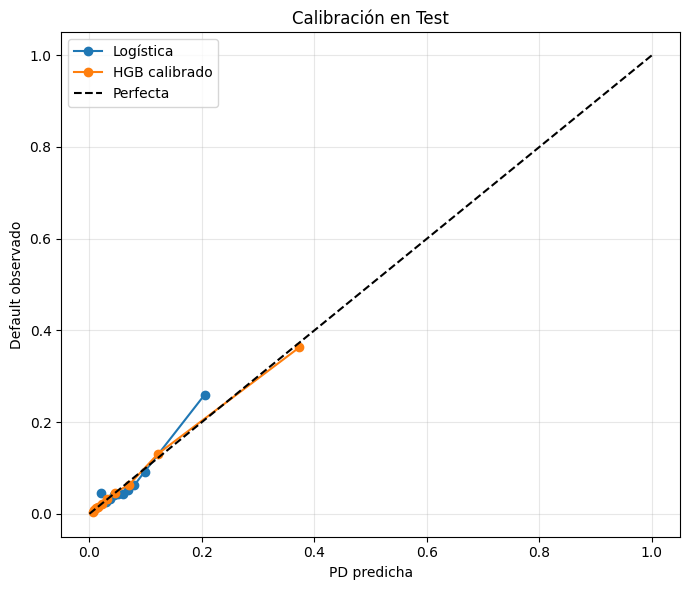

In [10]:
# Curvas de calibración
pt_lr, pp_lr = calibration_curve(y_test, p_lr_test, n_bins=10, strategy='quantile')
pt_hgb, pp_hgb = calibration_curve(y_test, p_cal_test, n_bins=10, strategy='quantile')

plt.figure(figsize=(7, 6))
plt.plot(pp_lr, pt_lr, 'o-', label='Logística')
plt.plot(pp_hgb, pt_hgb, 'o-', label='HGB calibrado')
plt.plot([0, 1], [0, 1], 'k--', label='Perfecta')
plt.xlabel('PD predicha')
plt.ylabel('Default observado')
plt.title('Calibración en Test')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 8. Convertir PD a score

No conviene hacer `score = 300 + (1-PD)*550`: esa transformación comprime de forma arbitraria el riesgo.

Una forma estándar de mantener interpretación es usar **odds** y `PDO` (Points to Double the Odds):

`score = BASE_SCORE + PDO * log2(odds / BASE_ODDS)`

con `odds = (1-PD)/PD`.

Los valores de `BASE_SCORE`, `BASE_ODDS` y `PDO` son parámetros de negocio; cambialos según el significado que quieras darle a la escala 300–850.

In [14]:
BASE_SCORE = 600
BASE_ODDS = 10.0   # 10 buenos por 1 malo => PD = 1 / 11 = 9.09%
PDO = 20.0         # +20 puntos = duplica odds buenos:malo


def pd_to_score(pd):
    pd = np.asarray(pd, dtype=float)
    pd = np.clip(pd, 1e-6, 1 - 1e-6)
    odds = (1 - pd) / pd
    score = BASE_SCORE + PDO * np.log2(odds / BASE_ODDS)
    return np.clip(score, 300, 850)


def score_to_pd(score):
    score = np.asarray(score, dtype=float)
    odds = BASE_ODDS * (2 ** ((score - BASE_SCORE) / PDO))
    return 1 / (1 + odds)

# Ejemplos para verificar la dirección.
for p in [0.90,0.50, 0.20, 0.10, 0.05, 0.01]:
    print(f'PD={p:>5.1%} -> score={pd_to_score(p):.1f}')

PD=90.0% -> score=470.2
PD=50.0% -> score=533.6
PD=20.0% -> score=573.6
PD=10.0% -> score=597.0
PD= 5.0% -> score=618.5
PD= 1.0% -> score=666.1


## 9. Pruebas automáticas de coherencia

Estas pruebas están diseñadas específicamente para el problema que describiste. El score debe responder en la dirección esperada cuando modificamos **una sola variable** y dejamos todas las demás iguales.

In [12]:
# Cliente base: mediana de cada variable, ajustada a valores razonables.
base = X_train.median(numeric_only=True).to_dict()
base = pd.DataFrame([base], columns=FEATURES)


def score_case(row):
    pd_pred = calibrated_model.predict_proba(row[FEATURES])[:, 1][0]
    return float(pd_pred), float(pd_to_score(pd_pred))


def compare_case(name, modified):
    p0, s0 = score_case(base)
    p1, s1 = score_case(modified)
    print(f'{name:<42} PD {p0:.4%} -> {p1:.4%} | Score {s0:.1f} -> {s1:.1f} | delta={s1-s0:+.1f}')

# Más ingreso: el score no debería bajar.
c = base.copy(); c.loc[0, 'ingreso_neto_mensual'] *= 1.20
compare_case('Ingreso +20%', c)

# Mayor DTI: el score no debería subir.
c = base.copy(); c.loc[0, 'relacion_deuda_ingreso'] *= 1.20
compare_case('DTI +20%', c)

# Mayor utilización: el score no debería subir.
c = base.copy(); c.loc[0, 'utilizacion_lineas'] *= 1.20
compare_case('Utilización +20%', c)

# Un atraso 90+: el score no debería subir.
c = base.copy(); c.loc[0, 'atraso_90_plus'] += 1
compare_case('Un atraso 90+ adicional', c)

Ingreso +20%                               PD 1.3110% -> 1.2439% | Score 658.2 -> 659.8 | delta=+1.5
DTI +20%                                   PD 1.3110% -> 1.3464% | Score 658.2 -> 657.5 | delta=-0.8
Utilización +20%                           PD 1.3110% -> 1.3554% | Score 658.2 -> 657.3 | delta=-1.0
Un atraso 90+ adicional                    PD 1.3110% -> 9.8945% | Score 658.2 -> 597.3 | delta=-60.9


## 10. Guardar modelo y configuración

Guardamos también la configuración de score. La aplicación debe usar exactamente el mismo conjunto de features y la misma fórmula PD → score.

In [13]:
ARTIFACT = {
    'model': calibrated_model,
    'features': FEATURES,
    'base_score': BASE_SCORE,
    'base_odds': BASE_ODDS,
    'pdo': PDO,
}

joblib.dump(ARTIFACT, r'credit_score_modelo_final.joblib')
print('Modelo guardado: credit_score_modelo_final.joblib')

Modelo guardado: credit_score_modelo_final.joblib
